# ND Week 6 — Decision Trees and Random Forests
**DX799 | Cindy Lopez**

**Question:** How well can these models predict customer conversion and campaign conversion counts? I use three datasets independently. The customer target is binary `Conversion`; the campaign targets are observed numerical `Conversions` counts, so I use regression for those two datasets. Metrics across different targets are not directly comparable.

## 1. Data loading, EDA and leakage safeguards
The uncleaned Google Ads file requires currency cleaning and missing-data treatment. Imputation, encoding and scaling are fitted only on training folds. I exclude identifiers, conversion-rate proxies, revenue and ROI from predictors to avoid outcome leakage.

In [10]:
import numpy as np, pandas as pd, os, warnings
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

FILES = {
 'Customer conversion': 'digital_marketing_campaign_dataset.csv',
 'Google Ads': 'GoogleAds_DataAnalytics_Sales_Uncleaned.csv',
 'Product performance': 'marketing_and_product_performance.csv'
}
for label, filename in FILES.items():
    if not os.path.isfile(filename):
        raise FileNotFoundError(f'Missing {filename}. Place all three CSVs in the notebook folder or upload them to Colab.')
print('All three CSV files found.')
data={name:pd.read_csv(filename) for name,filename in FILES.items()}
for name, df in data.items():
    print('\n',name,'shape:',df.shape,'missing cells:',int(df.isna().sum().sum()),'duplicates:',int(df.duplicated().sum()))
    display(df.head(2))
    display(df.isna().sum().sort_values(ascending=False).head(5).to_frame('missing'))
ads=data['Google Ads'].copy()
for col in ['Cost','Sale_Amount']:
    ads[col]=pd.to_numeric(ads[col].astype(str).str.replace(r'[$,]','',regex=True),errors='coerce')
for col in ['Clicks','Impressions','Leads','Conversions','Conversion Rate']:
    ads[col]=pd.to_numeric(ads[col],errors='coerce')
# I deliberately exclude Leads, Conversion Rate and Sale_Amount as outcome-adjacent or downstream variables.
config={
 'Customer conversion':{'frame':data['Customer conversion'],'target':'ConversionRate','numeric':['Age','Income','AdSpend','ClickThroughRate','WebsiteVisits','PagesPerVisit','TimeOnSite','SocialShares','EmailOpens','EmailClicks','PreviousPurchases','LoyaltyPoints'],'categorical':['Gender','CampaignChannel','CampaignType'],'poly':['AdSpend','ClickThroughRate','TimeOnSite']},
 'Google Ads':{'frame':ads,'target':'Conversions','numeric':['Clicks','Impressions','Cost'],'categorical':['Campaign_Name','Location','Device'],'poly':['Clicks','Impressions','Cost']},
 'Product performance':{'frame':data['Product performance'],'target':'Conversions','numeric':['Budget','Clicks','Discount_Level','Bundle_Price'],'categorical':['Subscription_Tier','Common_Keywords'],'poly':['Budget','Clicks','Discount_Level']}
}
for name,c in config.items():
    print(name,'target:',c['target'],'range:',c['frame'][c['target']].min(),c['frame'][c['target']].max())

All three CSV files found.

 Customer conversion shape: (8000, 20) missing cells: 0 duplicates: 0


,CustomerID,Age,Gender,Income,CampaignChannel,CampaignType,AdSpend,ClickThroughRate,ConversionRate,WebsiteVisits,PagesPerVisit,TimeOnSite,SocialShares,EmailOpens,EmailClicks,PreviousPurchases,LoyaltyPoints,AdvertisingPlatform,AdvertisingTool,Conversion
0,8000,56,Female,136912,Social Media,Awareness,6497.870068,0.043919,0.088031,0,2.399017,7.396803,19,6,9,4,688,IsConfid,ToolConfid,1
1,8001,69,Male,41760,Email,Retention,3898.668606,0.155725,0.182725,42,2.917138,5.352549,5,2,7,2,3459,IsConfid,ToolConfid,1


,missing
CustomerID,0
Age,0
AdvertisingTool,0
AdvertisingPlatform,0
LoyaltyPoints,0



 Google Ads shape: (2600, 13) missing cells: 1150 duplicates: 0


,Ad_ID,Campaign_Name,Clicks,Impressions,Cost,Leads,Conversions,Conversion Rate,Sale_Amount,Ad_Date,Location,Device,Keyword
0,A1000,DataAnalyticsCourse,104.0,4498.0,$231.88,14.0,7.0,0.058,$1892,2024-11-16,hyderabad,desktop,learn data analytics
1,A1001,DataAnalyticsCourse,173.0,5107.0,$216.84,10.0,8.0,0.046,$1679,20-11-2024,hyderabad,mobile,data analytics course


,missing
Conversion Rate,626
Sale_Amount,139
Clicks,112
Cost,97
Conversions,74



 Product performance shape: (10000, 17) missing cells: 0 duplicates: 0


,Campaign_ID,Product_ID,Budget,Clicks,Conversions,Revenue_Generated,ROI,Customer_ID,Subscription_Tier,Subscription_Length,Flash_Sale_ID,Discount_Level,Units_Sold,Bundle_ID,Bundle_Price,Customer_Satisfaction_Post_Refund,Common_Keywords
0,CMP_RLSDVN,PROD_HBJFA3,41770.45,4946,73,15520.09,1.94,CUST_1K7G39,Premium,4,FLASH_1VFK5K,43,34,BNDL_29U6W5,433.80,4,Affordable
1,CMP_JHHUE9,PROD_OE8YNJ,29900.93,570,510,30866.17,0.76,CUST_0DWS6F,Premium,4,FLASH_1M6COK,28,97,BNDL_ULV60J,289.29,2,Innovative


,missing
Campaign_ID,0
Subscription_Length,0
Customer_Satisfaction_Post_Refund,0
Bundle_Price,0
Bundle_ID,0


Customer conversion target: ConversionRate range: 0.0100177828330717 0.1999947079999166
Google Ads target: Conversions range: 3.0 10.0
Product performance target: Conversions range: 1 999


In [11]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, r2_score, mean_squared_error, mean_absolute_error, confusion_matrix
from IPython.display import display
import matplotlib.pyplot as plt

def ohe():
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)
def prep(c,scale=True):
    ns=[('impute',SimpleImputer(strategy='median'))]
    if scale: ns.append(('scale',StandardScaler()))
    return ColumnTransformer([('numeric',Pipeline(ns),c['numeric']),('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',ohe())]),c['categorical'])])

for name,c in config.items():
    target='Conversion' if name=='Customer conversion' else 'Conversions'
    y=pd.to_numeric(c['frame'][target],errors='coerce')
    print(name,'rows:',len(c['frame']),'target missing:',int(y.isna().sum()),'target median:',y.median(),'target std:',y.std())

Customer conversion rows: 8000 target missing: 0 target median: 1.0 target std: 0.3290308232678703
Google Ads rows: 2600 target missing: 74 target median: 7.0 target std: 2.2725732687366835
Product performance rows: 10000 target missing: 0 target median: 499.0 target std: 289.47949475584346


## 2. Decision trees versus random forests
A decision tree creates interpretable recursive partitions but can overfit. We constrain tree depth and minimum leaf size. A random forest averages predictions across bootstrapped trees and randomly sampled features to reduce variance. For the customer-level binary outcome we use classifiers; for campaign conversion counts we use regressors. All comparisons use an untouched 20% test set.

In [12]:
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
rows=[];details={}
for name,c in config.items():
    target='Conversion' if name=='Customer conversion' else 'Conversions'
    df=c['frame'].copy(); yy=pd.to_numeric(df[target],errors='coerce'); ok=yy.notna(); df=df.loc[ok]; yy=yy.loc[ok]
    cls=(name=='Customer conversion'); y=yy.astype(int) if cls else yy.astype(float)
    X=df[c['numeric']+c['categorical']]
    Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y if cls else None)
    for model_name in ['Decision tree','Random forest']:
        if cls:
            model=DecisionTreeClassifier(max_depth=5,min_samples_leaf=20,random_state=42) if model_name=='Decision tree' else RandomForestClassifier(n_estimators=120,max_depth=10,min_samples_leaf=5,random_state=42,n_jobs=-1)
        else:
            model=DecisionTreeRegressor(max_depth=5,min_samples_leaf=20,random_state=42) if model_name=='Decision tree' else RandomForestRegressor(n_estimators=120,max_depth=10,min_samples_leaf=5,random_state=42,n_jobs=-1)
        pipe=Pipeline([('prep',prep(c,scale=False)),('model',model)])
        pipe.fit(Xtr,ytr);p=pipe.predict(Xte)
        if cls:
            prob=pipe.predict_proba(Xte)[:,1]
            row={'dataset':name,'model':model_name,'train_accuracy':accuracy_score(ytr,pipe.predict(Xtr)),'test_accuracy':accuracy_score(yte,p),'balanced_accuracy':balanced_accuracy_score(yte,p),'F1_macro':f1_score(yte,p,average='macro'),'ROC_AUC':roc_auc_score(yte,prob),'minority_recall':((p[yte==0]==0).mean() if (yte==0).any() else np.nan)}
        else:
            row={'dataset':name,'model':model_name,'train_R2':r2_score(ytr,pipe.predict(Xtr)),'test_R2':r2_score(yte,p),'RMSE':np.sqrt(mean_squared_error(yte,p)),'MAE':mean_absolute_error(yte,p)}
        rows.append(row);details[(name,model_name)]=(Xtr,Xte,ytr,yte,p,pipe)
        print(name,model_name,'completed')
results=pd.DataFrame(rows);display(results.round(4))

Customer conversion Decision tree completed
Customer conversion Random forest completed
Google Ads Decision tree completed
Google Ads Random forest completed
Product performance Decision tree completed
Product performance Random forest completed


,dataset,model,train_accuracy,test_accuracy,balanced_accuracy,F1_macro,ROC_AUC,minority_recall,train_R2,test_R2,RMSE,MAE
0,Customer conversion,Decision tree,0.8939,0.8800,0.5629,0.5804,0.6921,0.1414,NaN,NaN,NaN,NaN
1,Customer conversion,Random forest,0.9184,0.8844,0.5415,0.5466,0.7928,0.0859,NaN,NaN,NaN,NaN
2,Google Ads,Decision tree,NaN,NaN,NaN,NaN,NaN,NaN,0.0187,-0.0257,2.2843,1.9750
3,Google Ads,Random forest,NaN,NaN,NaN,NaN,NaN,NaN,0.2526,-0.0299,2.2889,1.9740
4,Product performance,Decision tree,NaN,NaN,NaN,NaN,NaN,NaN,0.0187,-0.0177,293.5226,254.3638
5,Product performance,Random forest,NaN,NaN,NaN,NaN,NaN,NaN,0.1511,-0.0106,292.4926,253.3012


## 3. Hyperparameter tuning: random forest on customer conversions
I tune tree depth and minimum leaf size with three-fold stratified cross-validation using ROC-AUC. These control complexity: shallower trees and larger leaves reduce overfitting, while overly restrictive values may underfit. I compare CV scores with untouched test performance.

In [13]:
name='Customer conversion';c=config[name]
Xtr,Xte,ytr,yte,_,_=details[(name,'Random forest')]
pipe=Pipeline([('prep',prep(c,scale=False)),('model',RandomForestClassifier(n_estimators=120,random_state=42,n_jobs=-1))])
search=GridSearchCV(pipe,{'model__max_depth':[5,10],'model__min_samples_leaf':[5,20]},scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=42),n_jobs=1)
search.fit(Xtr,ytr);p=search.predict(Xte);prob=search.predict_proba(Xte)[:,1]
print('Best parameters:',search.best_params_,'CV ROC-AUC:',round(search.best_score_,4))
print('Test ROC-AUC:',round(roc_auc_score(yte,prob),4),'balanced accuracy:',round(balanced_accuracy_score(yte,p),4))
print('Confusion matrix:',confusion_matrix(yte,p).tolist())

Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 20} CV ROC-AUC: 0.8171
Test ROC-AUC: 0.7941 balanced accuracy: 0.5051
Confusion matrix: [[2, 196], [0, 1402]]


## 4. Interpretation and limitations
Compare train and test scores to identify overfitting. For imbalanced customer outcomes, overall accuracy can mask poor minority recall. ROC-AUC measures ranking quality and is not equivalent to performance at the 0.5 decision threshold. Campaign conversion counts are not the same outcome as individual customer conversion. This is predictive analysis; feature importance or model association is not causal attribution.

**Sources:** El Kharoua (2024), Nayak (2024), Shah (2024), Kaggle datasets. scikit-learn documentation: https://scikit-learn.org/stable/supervised_learning.html


## 5. Deeper analysis: model complexity and class-specific errors

The comparison above gives overall scores, but a stronger evaluation asks **how performance changes as a tree becomes more complex** and **which customers are misclassified**. We use the same held-out customer test set and vary tree depth. I inspect train versus test ROC-AUC rather than relying only on accuracy, because the classes are imbalanced. These diagnostics do not use the test set to select hyperparameters; tuning remains based on cross-validation in Section 3.

Tuned random forest — classification report:
              precision    recall  f1-score   support

           0      1.000     0.010     0.020       198
           1      0.877     1.000     0.935      1402

    accuracy                          0.877      1600
   macro avg      0.939     0.505     0.477      1600
weighted avg      0.893     0.877     0.821      1600



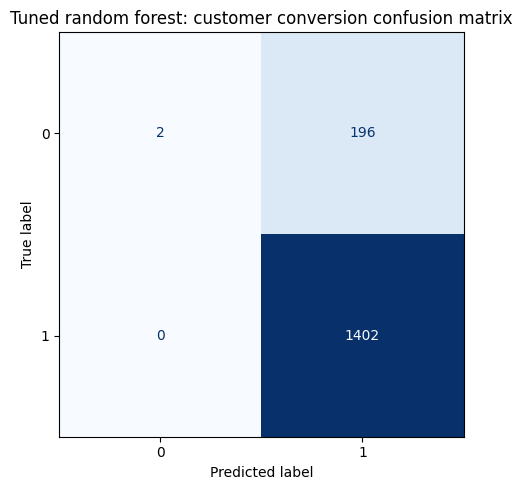

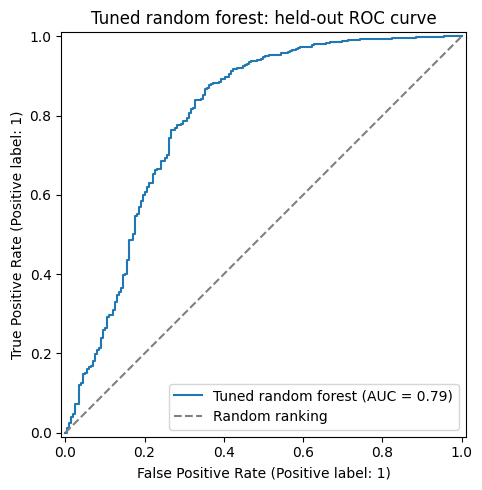

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

# Inspect the held-out predictions from the cross-validated random forest.
print('Tuned random forest — classification report:')
print(classification_report(yte, p, digits=3, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(yte, p, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Tuned random forest: customer conversion confusion matrix')
plt.tight_layout(); plt.show()

# ROC curve compares ranking ability across probability thresholds.
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(yte, prob, ax=ax, name='Tuned random forest')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
ax.set_title('Tuned random forest: held-out ROC curve')
ax.legend(); plt.tight_layout(); plt.show()

,max_depth,train_auc,test_auc
0,2,0.6743,0.6313
1,4,0.7565,0.6707
2,6,0.8290,0.7016
3,8,0.9124,0.6739
4,10,0.9580,0.6193
5,14,0.9777,0.6393
6,None,0.9786,0.6352


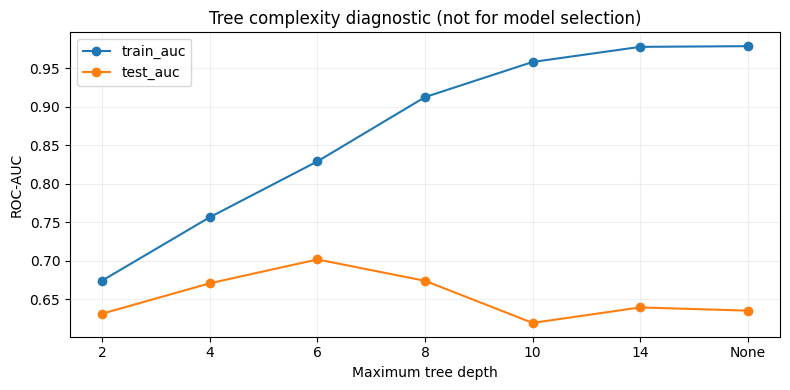

In [15]:
# Diagnostic only: show how model complexity changes training and held-out scores.
# Do not select depth based on this test-set plot; use training CV for selection.
depth_rows = []
for depth in [2, 4, 6, 8, 10, 14, None]:
    candidate = Pipeline([
        ('prep', prep(c, scale=False)),
        ('model', DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5, random_state=42))
    ])
    candidate.fit(Xtr, ytr)
    depth_rows.append({
        'max_depth': str(depth),
        'train_auc': roc_auc_score(ytr, candidate.predict_proba(Xtr)[:, 1]),
        'test_auc': roc_auc_score(yte, candidate.predict_proba(Xte)[:, 1])
    })
depth_results = pd.DataFrame(depth_rows)
display(depth_results.round(4))
ax = depth_results.plot(x='max_depth', y=['train_auc', 'test_auc'], marker='o', figsize=(8, 4))
ax.set(xlabel='Maximum tree depth', ylabel='ROC-AUC', title='Tree complexity diagnostic (not for model selection)')
ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()


## Enhanced Analysis: Cross-Validated Decision Tree Depth

### Research Question

How does decision-tree depth affect generalization, and can training-only cross-validation identify an appropriate level of model complexity?

The previous diagnostic showed increasing training ROC-AUC as tree depth increased, while held-out test ROC-AUC eventually declined. This pattern suggests overfitting.

However, selecting the best depth from repeated test-set evaluations would introduce selection bias. To address this limitation, I use stratified five-fold cross-validation on the training data to compare tree depths.

The depth with the highest mean cross-validation ROC-AUC is selected and then evaluated on the held-out test set. This separates hyperparameter selection from final model evaluation.


In [16]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd
import matplotlib.pyplot as plt

# Reuse the customer-conversion split from Week 6
name = "Customer conversion"
c = config[name]

Xtr, Xte, ytr, yte, _, _ = details[
    (name, "Random forest")
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

depth_rows_cv = []

for depth in [2, 4, 6, 8, 10, 14, None]:

    candidate = Pipeline([
        ("prep", prep(c, scale=False)),
        ("model", DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        ))
    ])

    scores = cross_validate(
        candidate,
        Xtr,
        ytr,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1
    )

    depth_rows_cv.append({
        "max_depth": str(depth),
        "train_cv_auc": scores["train_score"].mean(),
        "validation_cv_auc": scores["test_score"].mean(),
        "validation_cv_std": scores["test_score"].std()
    })

depth_cv_results = pd.DataFrame(depth_rows_cv)

display(depth_cv_results.round(4))

# Select depth using validation folds, NOT the test set
best_row = depth_cv_results.loc[
    depth_cv_results["validation_cv_auc"].idxmax()
]

best_depth = (
    None if best_row["max_depth"] == "None"
    else int(best_row["max_depth"])
)

print("CV-selected depth:", best_depth)
print(
    "Mean validation ROC-AUC:",
    round(best_row["validation_cv_auc"], 4)
)

# Fit the selected model on the full training set
final_tree = Pipeline([
    ("prep", prep(c, scale=False)),
    ("model", DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=5,
        random_state=42
    ))
])

final_tree.fit(Xtr, ytr)

# Evaluate once using the held-out test set
test_prob = final_tree.predict_proba(Xte)[:, 1]

final_test_auc = roc_auc_score(yte, test_prob)

print(
    "CV-selected tree test ROC-AUC:",
    round(final_test_auc, 4)
)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for 

,max_depth,train_cv_auc,validation_cv_auc,validation_cv_std
0,2,0.6782,0.6609,0.0187
1,4,0.7658,0.7053,0.0236
2,6,0.8399,0.7204,0.0295
3,8,0.9141,0.6936,0.0216
4,10,0.9564,0.6662,0.0158
5,14,0.9763,0.6824,0.0178
6,None,0.9774,0.6875,0.0155


CV-selected depth: 6
Mean validation ROC-AUC: 0.7204
CV-selected tree test ROC-AUC: 0.7016



### Cross-Validation Results and Model Selection

Five-fold stratified cross-validation identified a maximum tree depth of 6 as the best-performing configuration among the tested values, with a mean validation ROC-AUC of 0.7204 and a standard deviation of 0.0295.

At depth 6, mean training ROC-AUC was 0.8399, producing a training–validation gap of 0.1195. In contrast, the unrestricted tree achieved a much higher training ROC-AUC of 0.9774 but a lower validation ROC-AUC of 0.6875, resulting in a gap of 0.2899.

This comparison provides evidence of overfitting: increasing tree complexity improved performance on the training folds but did not improve performance on unseen validation folds.

Although depth 6 produced the highest mean cross-validation score, its advantage over depth 4 was relatively small. Therefore, the result should be interpreted as support for moderate tree complexity rather than proof of a universally optimal depth.

The experiment demonstrates the importance of controlling model complexity and selecting hyperparameters through cross-validation instead of relying on training performance alone.


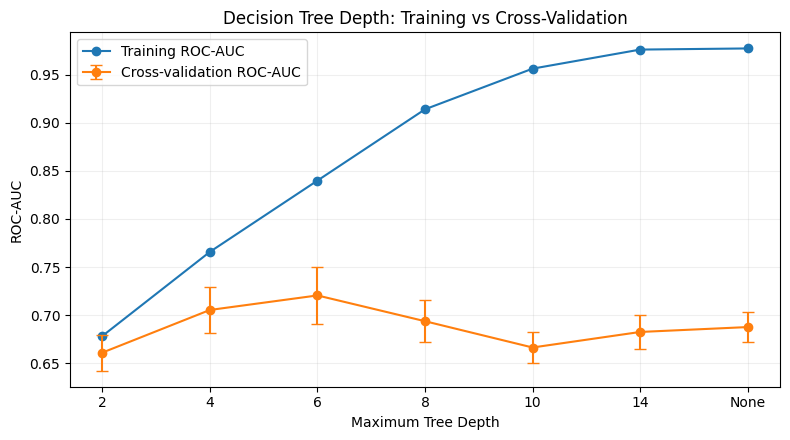

In [17]:

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    depth_cv_results["max_depth"],
    depth_cv_results["train_cv_auc"],
    marker="o",
    label="Training ROC-AUC"
)

ax.errorbar(
    depth_cv_results["max_depth"],
    depth_cv_results["validation_cv_auc"],
    yerr=depth_cv_results["validation_cv_std"],
    marker="o",
    capsize=4,
    label="Cross-validation ROC-AUC"
)

ax.set_title(
    "Decision Tree Depth: Training vs Cross-Validation"
)
ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("ROC-AUC")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()



### Interpretation: Tree Depth, Overfitting, and Generalization

The cross-validation experiment demonstrates how increasing decision-tree complexity can improve training performance without improving generalization.

At shallow depths, the decision tree produced relatively similar training and validation ROC-AUC values. As maximum depth increased, training ROC-AUC rose steadily, eventually approaching 0.98 for the deepest configurations. However, cross-validation ROC-AUC did not follow the same pattern.

Validation performance improved from approximately 0.66 at depth 2 to approximately 0.72 at depth 6, before declining at greater depths. This suggests that moderate tree complexity captured useful relationships while limiting the model's tendency to fit training-specific patterns.

The widening difference between training and validation ROC-AUC provides evidence of overfitting. Deeper trees became increasingly effective at separating observations within the training folds but less effective at generalizing to unseen validation folds.

This analysis also demonstrates why hyperparameter selection should rely on cross-validation rather than repeated test-set comparisons. Cross-validation evaluates model complexity using training data, allowing the held-out test set to serve as a separate final assessment.

The findings support the broader capstone conclusion that increasing model complexity does not necessarily improve predictive usefulness. In this experiment, constraining tree depth provided a more favorable balance between training fit and validation performance.



### Final Model Evaluation and Practical Implications

Five-fold stratified cross-validation selected a maximum decision-tree depth of 6, with a mean validation ROC-AUC of 0.7204. When the selected model was fitted to the full training set and evaluated on the held-out test set, it achieved a ROC-AUC of 0.7016.

The difference of 0.0188 between mean validation and test ROC-AUC suggests that the cross-validation estimate was reasonably consistent with the model's performance on unseen observations.

The results also demonstrate the risks of excessive model complexity. Although an unrestricted tree achieved a mean training ROC-AUC of 0.9774, its mean validation ROC-AUC was only 0.6875. In contrast, the depth-6 tree achieved a lower training ROC-AUC of 0.8399 but a higher mean validation ROC-AUC of 0.7204.

This supports the conclusion that controlling tree depth can reduce overfitting and improve generalization.

However, ROC-AUC measures ranking performance across classification thresholds rather than the number of non-converting customers correctly identified at a particular threshold. Therefore, the model's practical usefulness must also be considered alongside minority-class recall, precision, and the costs associated with incorrect predictions.

An important limitation is that the earlier exploratory analysis inspected test performance at multiple depths. Although the final depth was selected using training-only cross-validation, the test set was not entirely untouched during the broader investigation.

Overall, the experiment demonstrates that a moderately complex model can generalize better than a highly flexible model, even when the more complex model performs substantially better on training data.


### AI Assited Interpretation prompts for the final report

After running these cells, record the **actual values** before drafting the Milestone One conclusions:

- At which depths does training ROC-AUC rise while test ROC-AUC stagnates or declines? That is evidence of overfitting.
- How many non-converting customers are correctly identified? Why might overall accuracy conceal that result?
- Does the tuned forest improve ROC-AUC relative to the untuned forest? Is that improvement large enough to matter for a marketing decision?
- Why might a different classification threshold be appropriate if the cost of missing a non-converter differs from the cost of a false alarm?

These are diagnostic questions, not conclusions assumed in advance. Do not claim improvements unless the executed outputs support them.